In [1]:
#PROBLEMATIQUE:
#Peut-on prédire les concentrations de NO₂ à partir des mesures des capteurs chimiques et des conditions météorologiques dans la ville de Milan ?
#IMPORTATION DE BIBLIOTHEQUES: 
import numpy as np 
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from sklearn.linear_model import LinearRegression 
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score

In [2]:
#Chargement de données: 
df=pd.read_excel("AirQuality_propre.xlsx")
df.head().round(2)

,CO(GT),PT08.S1(CO),C6H6(GT),PT08.S2(NMHC),NOx(GT),PT08.S3(NOx),NO2(GT),PT08.S4(NO2),PT08.S5(O3),T,RH,AH,datetime,is_outlier,Year,Month,Day,Hour,Season
0,2.6,1360,11.9,1046,166,1056,113,1692,1268,13.6,48.9,0.76,2004-03-10 18:00:00,0,2004,3,10,18,Spring
1,2.0,1292,9.4,955,103,1174,92,1559,972,13.3,47.7,0.73,2004-03-10 19:00:00,1,2004,3,10,19,Spring
2,2.2,1402,9.0,939,131,1140,114,1555,1074,11.9,54.0,0.75,2004-03-10 20:00:00,1,2004,3,10,20,Spring
3,2.2,1376,9.2,948,172,1092,122,1584,1203,11.0,60.0,0.79,2004-03-10 21:00:00,1,2004,3,10,21,Spring
4,1.6,1272,6.5,836,131,1205,116,1490,1110,11.2,59.6,0.79,2004-03-10 22:00:00,1,2004,3,10,22,Spring


In [3]:
#EXPLOITATION DES DONNEES:
print(df.info())
print(df.describe().round(2))

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9358 entries, 0 to 9357
Data columns (total 19 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   CO(GT)         9358 non-null   float64       
 1   PT08.S1(CO)    9358 non-null   int64         
 2   C6H6(GT)       9358 non-null   float64       
 3   PT08.S2(NMHC)  9358 non-null   int64         
 4   NOx(GT)        9358 non-null   int64         
 5   PT08.S3(NOx)   9358 non-null   int64         
 6   NO2(GT)        9358 non-null   int64         
 7   PT08.S4(NO2)   9358 non-null   int64         
 8   PT08.S5(O3)    9358 non-null   int64         
 9   T              9358 non-null   float64       
 10  RH             9358 non-null   float64       
 11  AH             9358 non-null   float64       
 12  datetime       9358 non-null   datetime64[ns]
 13  is_outlier     9358 non-null   int64         
 14  Year           9358 non-null   int64         
 15  Month          9358 n

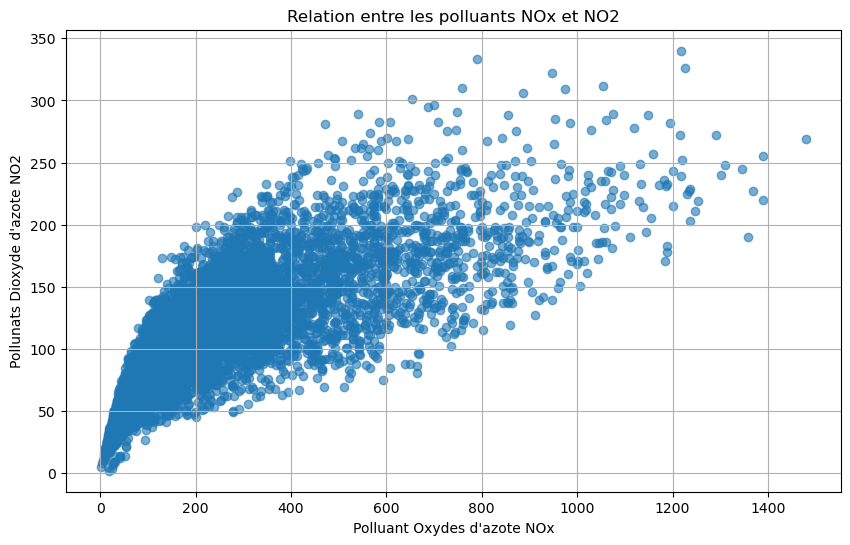

In [4]:
#VISUALISATION DE LA RELATION: ETAT DE COURBE DE REGRESSION.
plt.figure(figsize=(10, 6))
plt.scatter(df["NOx(GT)"], df["NO2(GT)"], alpha=0.6)
plt.title("Relation entre les polluants NOx et NO2")
plt.xlabel("Polluant Oxydes d'azote NOx")
plt.ylabel("Pollunats Dioxyde d'azote NO2")
plt.grid(True)
plt.show()

#COMMENTAIRE:
#Une relation positive indique qu'une augmentation des oxydes d'azote est associée à une hausse du dioxyde d'azote.
#Le graphique ci-dessus est un nuage de points (scatter plot) qui montre comment évolue le NO2 en fonction NOx
#A l'allure de la courbe, on peut conclure que le NO2 est en forte correlatuon avec le NOx, lorque e NO2 augemente, le NOX augmente aussi vis versa. 

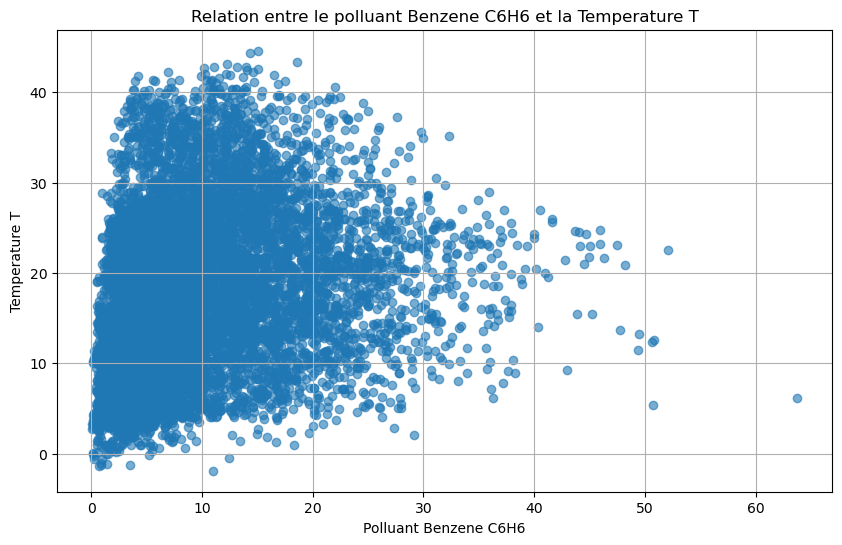

In [5]:
plt.figure(figsize=(10, 6))
plt.scatter(df["C6H6(GT)"], df["T"], alpha=0.6)
plt.title("Relation entre le polluant Benzene C6H6 et la Temperature T")
plt.xlabel("Polluant Benzene C6H6")
plt.ylabel("Temperature T")
plt.grid(True)
plt.show()
#Une relation négative est observée entre le benzène (C6H6) et la température. Les concentrations de benzène tendent à être plus élevées durant les périodes froides et plus faibles lorsque la température augmente.

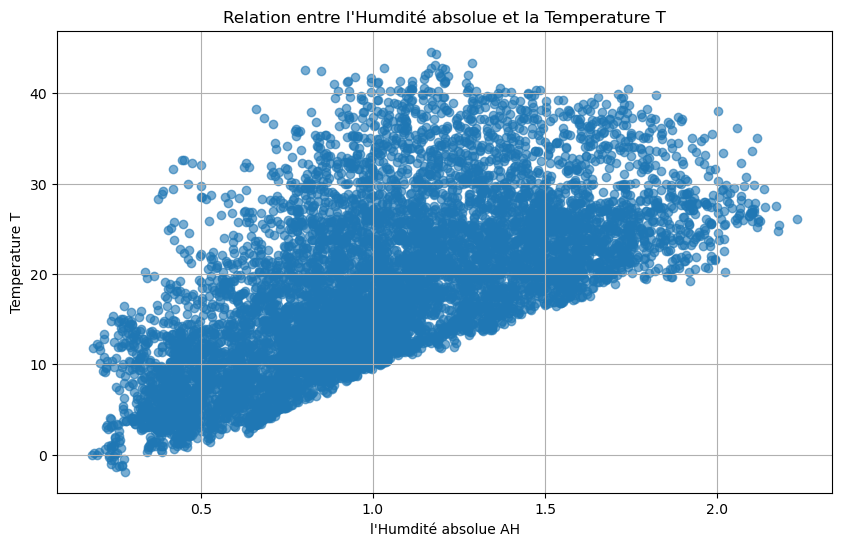

In [6]:
plt.figure(figsize=(10, 6))
plt.scatter(df["AH"], df["T"], alpha=0.6)
plt.title("Relation entre l'Humdité absolue et la Temperature T")
plt.xlabel("l'Humdité absolue AH")
plt.ylabel("Temperature T")
plt.grid(True)
plt.show()
#Une corrélation positive est observée entre la température et l'humidité absolue. Lorsque la température augmente, l'air peut contenir davantage de vapeur d'eau, ce qui entraîne une augmentation de l'humidité absolue.

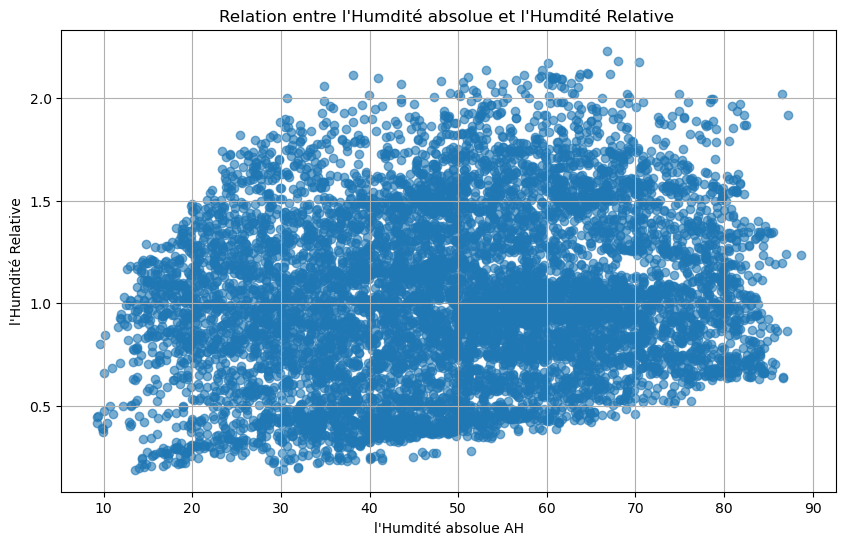

In [7]:
plt.figure(figsize=(10, 6))
plt.scatter(df["RH"], df["AH"], alpha=0.6)
plt.title("Relation entre l'Humdité absolue et l'Humdité Relative ")
plt.xlabel("l'Humdité absolue AH")
plt.ylabel("l'Humdité Relative")
plt.grid(True)
plt.show()
#Les valeurs élevées d'humidité absolue sont généralement associées à des valeurs plus importantes d'humidité relative. Toutefois, la dispersion des observations montre que la température joue également un rôle important dans cette relation.

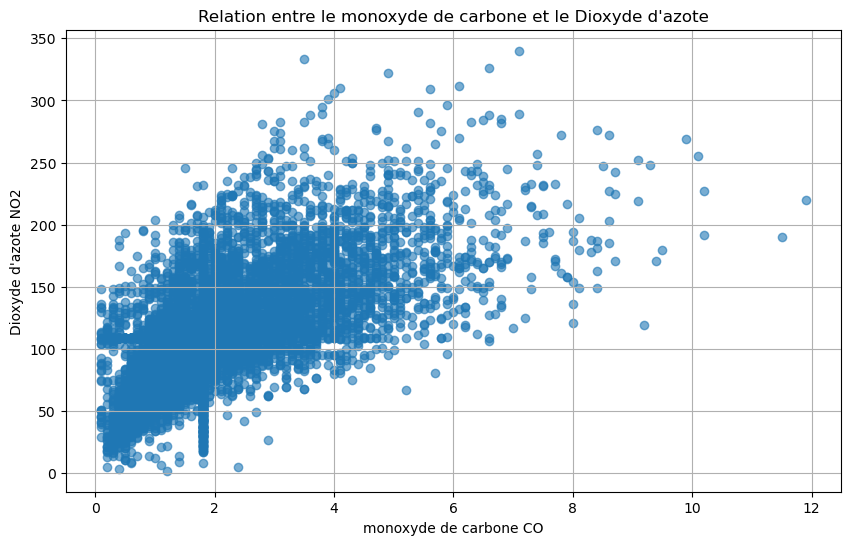

In [8]:
plt.figure(figsize=(10, 6))
plt.scatter(df["CO(GT)"], df["NO2(GT)"], alpha=0.6)
plt.title("Relation entre le monoxyde de carbone et le Dioxyde d'azote")
plt.xlabel("monoxyde de carbone CO")
plt.ylabel("Dioxyde d'azote NO2")
plt.grid(True)
plt.show()
#Une relation positive est observée entre le monoxyde de carbone et le dioxyde d'azote. Ces polluants proviennent souvent des mêmes sources d'émission, notamment le trafic routier.

In [9]:
#SEPARATION DE DONNEES: REALISATION DU TEST ET ENTRAINEMENT SUR LES DONNEES
# Variable cible
y=df["NO2(GT)"]
# Variables explicatives
X= df.drop(columns=["NO2(GT)", "datetime"])
# Encodage de la variable catégorielle Season
X=pd.get_dummies(X, columns=["Season"], drop_first=True)

# Séparation des données
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20,random_state=42)

In [10]:
#ENTRAINEMENT DU MODELE DE RGRESSION LINEAIRE:
#CONTRUCTION DU MODELE:
model=LinearRegression()
model.fit(X_train, y_train)

df= pd.DataFrame({"Variables": X.columns,"Coefficients": model.coef_.round(2)})
print(df.sort_values(by='Coefficients', key=abs, ascending=False))

#Ce que l'on peut retenir
#AH (-18.78) : l'humidité absolue est la variable ayant l'effet négatif le plus important sur NO₂. Lorsque AH augmente d'une unité, NO₂ tend à diminuer.
#CO(GT) (+4.93) : plus le monoxyde de carbone augmente, plus le NO₂ augmente. Cela est logique car ils proviennent souvent des mêmes sources (trafic, combustion).
#Season_Spring (-3.86) : au printemps, le NO₂ est en moyenne plus faible que dans la saison de référence (probablement l'automne si tu as utilisé drop_first=True).
#NOx(GT) (+0.12) : effet positif attendu puisque NOx et NO₂ sont chimiquement liés.
#Month (-2.47) : indique une variation saisonnière progressive du NO₂.

#Conclusion: 
#Les variables les plus influentes dans la prédiction du NO₂ sont l'humidité absolue (AH), le CO(GT), la saison et le NOx(GT). Le CO et le NOx présentent une influence positive sur les concentrations de NO₂, tandis que l'humidité absolue exerce une influence négative. Ces résultats sont cohérents avec les mécanismes atmosphériques et les sources communes de pollution urbaine.

        Variables  Coefficients
10             AH        -24.36
12           Year         15.85
0          CO(GT)          4.64
2        C6H6(GT)         -4.41
16  Season_Spring         -3.82
17  Season_Summer          1.36
13          Month         -0.99
18  Season_Winter         -0.75
15           Hour          0.42
9              RH         -0.30
8               T          0.23
11     is_outlier          0.14
4         NOx(GT)          0.12
3   PT08.S2(NMHC)          0.10
14            Day          0.04
7     PT08.S5(O3)          0.02
1     PT08.S1(CO)         -0.01
6    PT08.S4(NO2)          0.01
5    PT08.S3(NOx)         -0.01


In [11]:
#PREDICTION ET EVALUATION DU MODELE:
y_pred = model.predict(X_test)
#Calcul coefficient de determination et erreur quadratique moyenne:
R2=r2_score(y_test, y_pred).round(2)
MSE=mean_squared_error(y_test, y_pred).round(2)
print(f"Coeficient de Determination : {R2:.2f}")
print(f"Erreur Quadratique Moyenne : {MSE:.2f}")
#Le modele a pu interpreter pret de 75% des information de la variabiliuté de NO2, à peine 25% non interpreter d'ou l'efficacité de mon modele de regression lineaire.

Coeficient de Determination : 0.75
Erreur Quadratique Moyenne : 475.50


In [12]:
#Comprehension de données:
print("X_train :", X_train.shape)
print("X_test :", X_test.shape)
print("y_train :", y_train.shape)
print("y_test :", y_test.shape)
print("y_pred :", y_pred.shape)

X_train : (7486, 19)
X_test : (1872, 19)
y_train : (7486,)
y_test : (1872,)
y_pred : (1872,)


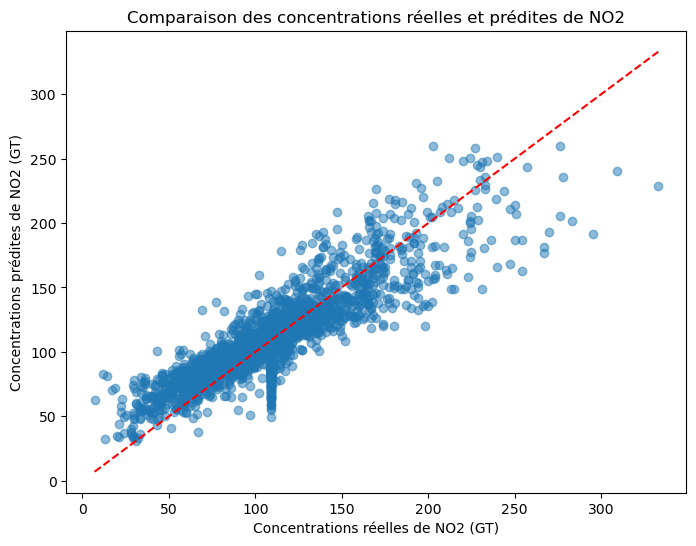

In [13]:
#EVALUATION DU MODELE: 
y_pred=model.predict(X_test)
# Visuel scatter de notre modele predit:
plt.figure(figsize=(8,6))
plt.scatter(y_test, y_pred, alpha=0.5)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--')
plt.xlabel("Concentrations réelles de NO2 (GT)")
plt.ylabel("Concentrations prédites de NO2 (GT)")
plt.title("Comparaison des concentrations réelles et prédites de NO2")
plt.show()
#Le nuage de points montre une proximité globale entre les valeurs observées et les valeurs prédites. La concentration des points autour de la diagonale traduit une bonne capacité du modèle à reproduire les variations des concentrations de NO₂. Cette observation est cohérente avec le coefficient de détermination obtenu (R² = 0,74), indiquant que le modèle explique 74 % de la variabilité de la variable cible.

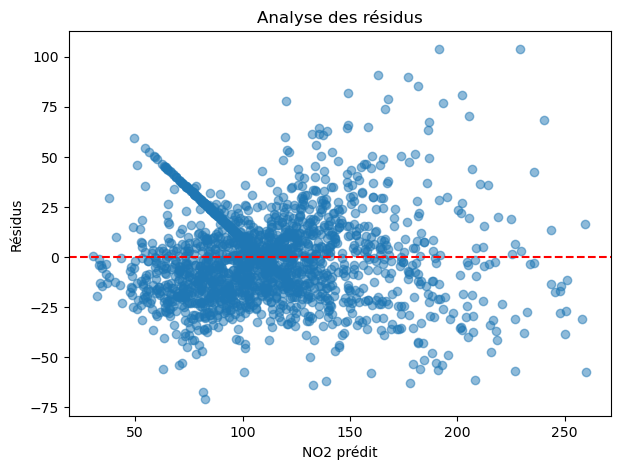

In [14]:
residus = y_test - y_pred
plt.figure(figsize=(7,5))
plt.scatter(y_pred, residus, alpha=0.5)

plt.axhline(y=0, color='red', linestyle='--')

plt.xlabel("NO2 prédit")
plt.ylabel("Résidus")
plt.title("Analyse des résidus")
plt.show()

In [15]:
#PREDICTION PERSONNALISEE AVEC LE MODEL:
input_df = X.iloc[[0]].copy()
prediction = model.predict(input_df)
print("NO2 prédit :", round(prediction[0],2))

NO2 prédit : 116.69


In [16]:
print(len(y_pred))
print(len(y_test))

1872
1872


In [17]:
#Telechargement de la version Excel:
df.to_excel("AirQuality_propre_M.xlsx", index=False)

In [18]:
df.to_excel("coefficients_regression_Linear.xlsx", index=False)

In [19]:
performance_df=pd.DataFrame({"Indicateur": ["R2", "MSE"],"Valeur": [R2, MSE]})
performance_df.to_excel("performance_modele.xlsx", index=False)

In [49]:
resultats=pd.DataFrame({"NO2_Reel": y_test,"NO2_Prédit": y_pred})

resultats.to_excel("NO2_Reel_Prédit.xlsx",index=False)